# Load arrays and Lightkurve objects

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
import lightkurve as lk

print(f"Nāhiku {nahiku.__version__}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


/tmp/nahiku-02/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


Input observations: 24; retained observations: 23
Original row indices in time order: [15, 13, 7, 16, 5, 12, 10, 0, 9, 19, 14, 8, 21, 11, 22, 3, 17, 18, 23, 1, 4, 20, 6]


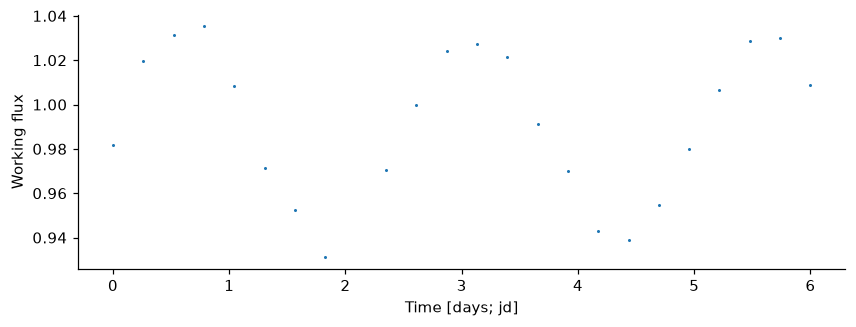

In [ ]:
# Generate 24 observations with a reproducible signal and measurement noise.
rng = np.random.default_rng(48)
time = np.linspace(0, 6, 24)
flux = 1 + 0.05 * np.sin(2 * np.pi * time / 2.5) + rng.normal(0, 0.005, time.size)
flux_err = np.full(time.size, 0.005)

# Include one invalid flux and shuffle the rows to demonstrate cleaning and sorting.
flux[8] = np.nan
order = rng.permutation(time.size)
observed = lk.LightCurve(time=time[order], flux=flux[order], flux_err=flux_err[order])

# Convert to Nahiku; default normalization divides flux by its retained median.
lc = Nahiku.from_lightkurve(observed)
print(f"Input observations: {len(observed)}; retained observations: {len(lc.time)}")
print("Original row indices in time order:", lc.metadata["source_indices"])
lc.plot();

## Interpret the result
Conversion removes invalid samples and rejects duplicate timestamps. For archive retrieval use `Nahiku.download(target, mission=..., author=..., exptime=..., quarter=.../sector=...)`.

Consult the API reference for parameter and return-value details.
